# Lifestyle, Biology and Socioeconomic Status in Diabetes: A Hypothesis-Driven Analysis

**Data:** 100,000 individual-level records, 31 variables (demographics, SES, lifestyle, anthropometrics, clinical labs, diagnosis).
**Approach:** pre-specified hypotheses (H0/H1), Welch t-tests and chi-square tests, **effect sizes with confidence intervals**, Holm correction for multiple testing, equivalence (TOST) tests for null findings, then an adjusted model and a prediction benchmark.

> Why effect sizes first? With n = 100,000, almost any difference is "statistically significant". The scientific question is *how big* an association is and whether it matters, so every result below is reported as an effect size with a 95% CI, not only a p-value.

> **Important caveat:** this dataset appears to be synthetic or simulated (see Section 1). Results describe associations in *this* file, not causal effects in a real population.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
import hypotheses as H
from analysis_utils import load_data

pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid")
df = load_data("../data/raw/diabetes_dataset.csv")
df.shape

(100000, 31)

## 1. Data quality and construction checks

In [2]:
dq = H.data_quality(df)
print({k: v for k, v in dq.items() if k != "stage_vs_diagnosed"})
dq["stage_vs_diagnosed"]

{'n': 100000, 'missing_cells': 0, 'duplicate_rows': 0, 'prevalence_diagnosed': 0.59998, 'stage_counts': {'Type 2': 59774, 'Pre-Diabetes': 31845, 'No Diabetes': 7981, 'Gestational': 278, 'Type 1': 122}, 'share_hba1c_ge_6_5_among_t2': 0.8518921270117442, 'share_hba1c_ge_6_5_overall': 0.51105}


diagnosed_diabetes,0,1
diabetes_stage,,
Gestational,120,158
No Diabetes,7981,0
Pre-Diabetes,31845,0
Type 1,56,66
Type 2,0,59774


**What the checks show**

- No missing values and no duplicate rows.
- `diagnosed_diabetes` = 1 for all Type 2 patients, 0 for all Pre-Diabetes / No Diabetes, and mixed for the very small Type 1 and Gestational groups. Pre-diabetes is therefore coded as *not diagnosed*.
- 60% of the sample is diagnosed, far above any real adult population (roughly 10-15%), so the sample is either enriched or simulated.
- Income, education, smoking and ethnicity show essentially **zero** relationship with diagnosis (Section 3). Real data nearly always show such gradients, another sign the file is synthetic.

I treat this as a *methods demonstration*: the pipeline is what matters, and every conclusion is scoped to this dataset.

## 2. Hypotheses

Seven confirmatory hypotheses, grouped into behaviour, biology and socioeconomic status. All tests are two-sided, alpha = 0.05, Holm-corrected across the family of seven.

| ID | H0 | H1 | Outcome | Test |
|---|---|---|---|---|
| H1 | No HbA1c difference between people meeting the WHO guideline (150+ min/wk) and those who do not | Active group has lower HbA1c | HbA1c | Welch t-test, Cohen's d |
| H2 | No HbA1c difference between top and bottom diet-score quartiles | Top quartile differs | HbA1c | Welch t-test, Cohen's d |
| H3 | Diagnosis rate is equal with/without family history | Family history raises it | Diagnosis | Chi-square, odds ratio |
| H4 | No HbA1c difference by obesity (BMI >= 30) | Obese group has higher HbA1c | HbA1c | Welch t-test, Cohen's d |
| H5 | Diagnosis rate is equal across income levels | It differs | Diagnosis | Chi-square, Cramer's V |
| H6 | Diagnosis rate is equal across education levels | It differs | Diagnosis | Chi-square, Cramer's V |
| H7 | No HbA1c difference between current and never smokers | It differs | HbA1c | Welch t-test, Cohen's d |

*Why Welch rather than a plain t-test or z-test?* Group sizes and variances differ, and Welch does not assume equal variances. With n this large a z-test would give nearly identical answers; what matters is not relying on a normality shortcut.

In [3]:
main, eq = H.confirmatory_tests(df)
main[["id","domain","effect_measure","effect_size","es_low","es_high","estimate","ci_low","ci_high","p_raw","p_holm","reject_h0","size_label"]]

,id,domain,effect_measure,effect_size,es_low,es_high,estimate,ci_low,ci_high,p_raw,p_holm,reject_h0,size_label
0,H1,Behaviour,Cohen's d,-0.2092,-0.2229,-0.1954,-0.1695,-0.1806,-0.1583,0.0000,0.0000,True,small
1,H2,Behaviour,Cohen's d,-0.1328,-0.1500,-0.1157,-0.1079,-0.1218,-0.0940,0.0000,0.0000,True,negligible
2,H3,Biology,Odds ratio,2.9671,2.8649,3.0729,0.2343,0.2278,0.2408,0.0000,0.0000,True,strong
3,H4,Biology,Cohen's d,0.2274,0.2078,0.2469,0.1846,0.1688,0.2003,0.0000,0.0000,True,small
4,H5,Socioeconomic,Cramer's V,0.0066,NaN,NaN,-0.0066,-0.0223,0.0090,0.3554,1.0000,False,negligible
5,H6,Socioeconomic,Cramer's V,0.0058,NaN,NaN,0.0110,-0.0046,0.0266,0.3401,1.0000,False,negligible
6,H7,Behaviour,Cohen's d,0.0021,-0.0138,0.0181,0.0017,-0.0112,0.0147,0.7917,1.0000,False,negligible


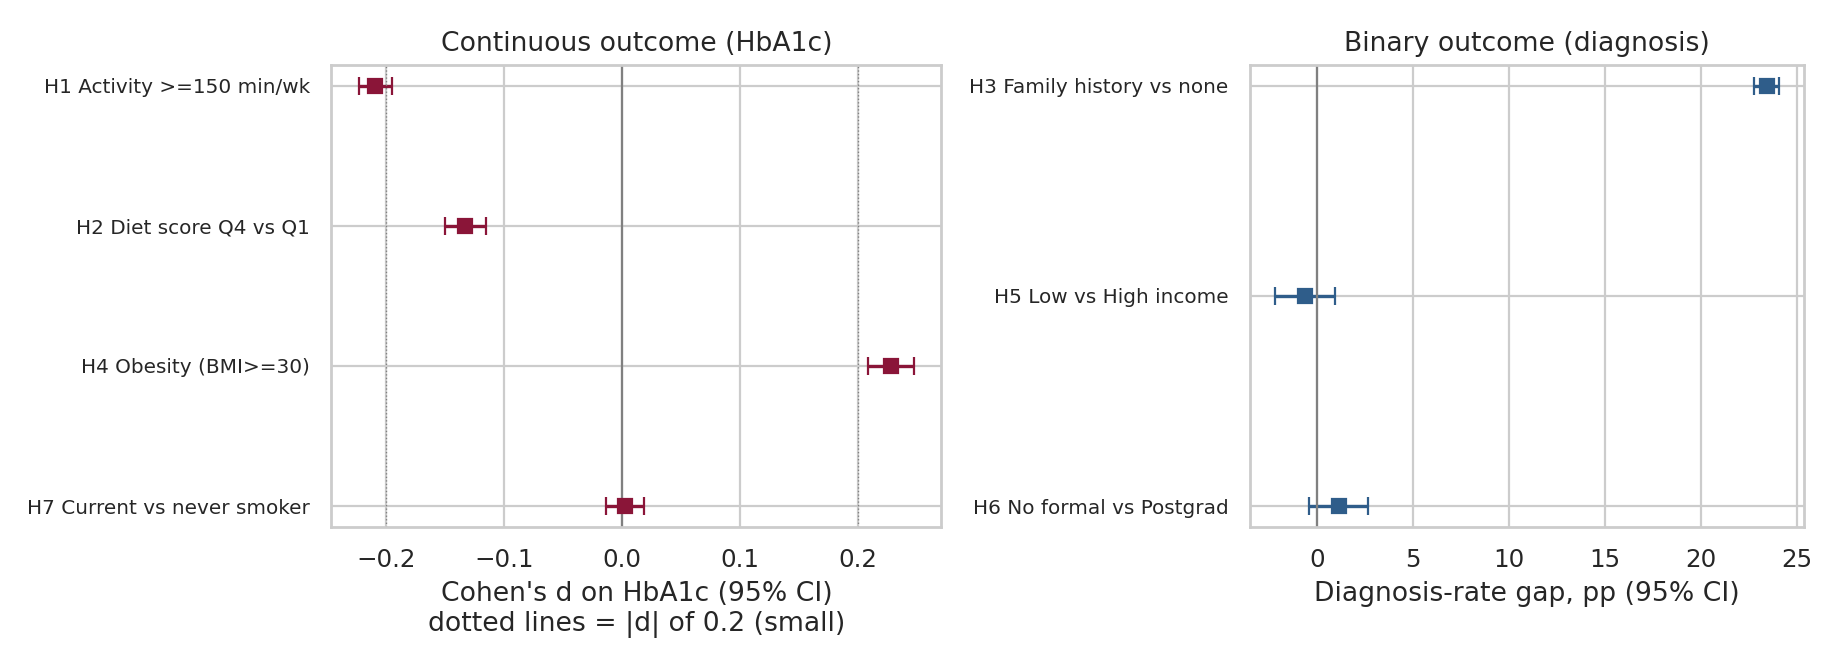

In [4]:
display(Image('../results/figures/02_effect_sizes_forest.png'))

### Reading the results

| ID | Finding | Effect size | Verdict |
|---|---|---|---|
| H1 | Meeting the activity guideline is associated with HbA1c about **0.17 points lower** | d = -0.21 (small) | Reject H0 |
| H2 | Top-quartile diet is associated with HbA1c about **0.11 points lower** | d = -0.13 (below the 0.2 "small" threshold) | Reject H0 |
| H3 | Family history is the strongest non-glycaemic predictor: diagnosis rate **23 pp higher** | OR = 2.97 | Reject H0 |
| H4 | Obesity is associated with HbA1c about **0.18 points higher** | d = 0.23 (small) | Reject H0 |
| H5 | No income gradient in diagnosis | V = 0.007 | Fail to reject |
| H6 | No education gradient in diagnosis | V = 0.006 | Fail to reject |
| H7 | No smoking difference in HbA1c | d = 0.002 | Fail to reject |

Holm-adjusted p-values for H1-H4 are effectively zero; for H5-H7 they are 1.0 (raw p = 0.36, 0.34, 0.79). Note that H1, H2 and H4 are statistically unambiguous but **small in size**: their effects sit around 0.1-0.2 standard deviations.

## 3. Are the null results really "no effect"? Equivalence tests

Failing to reject H0 does not show there is no effect, only that we could not detect one. With n = 100,000 we can do better and test whether the effect is **provably small** (TOST). Margins are a judgement call, stated up front: **+/- 3 percentage points** for diagnosis rates and **+/- 0.10** HbA1c points for smoking.

In [5]:
eq

,id,comparison,margin,p_tost,ci90_low,ci90_high,equivalent
0,H5,Low vs High income (diagnosis rate),0.0300,0.0017,-0.0198,0.0065,True
1,H6,No formal vs Postgraduate (diagnosis rate),0.0300,0.0083,-0.0021,0.0241,True
2,H7,Current vs never smokers (HbA1c),0.1000,0.0000,-0.0091,0.0126,True


All three nulls pass equivalence: the income gap, education gap and smoking gap are each demonstrably inside the margin. In this dataset, socioeconomic status and smoking are **not** where the action is, which is the opposite of what the real-world literature would lead us to expect. That contrast is itself informative about the data-generating process.

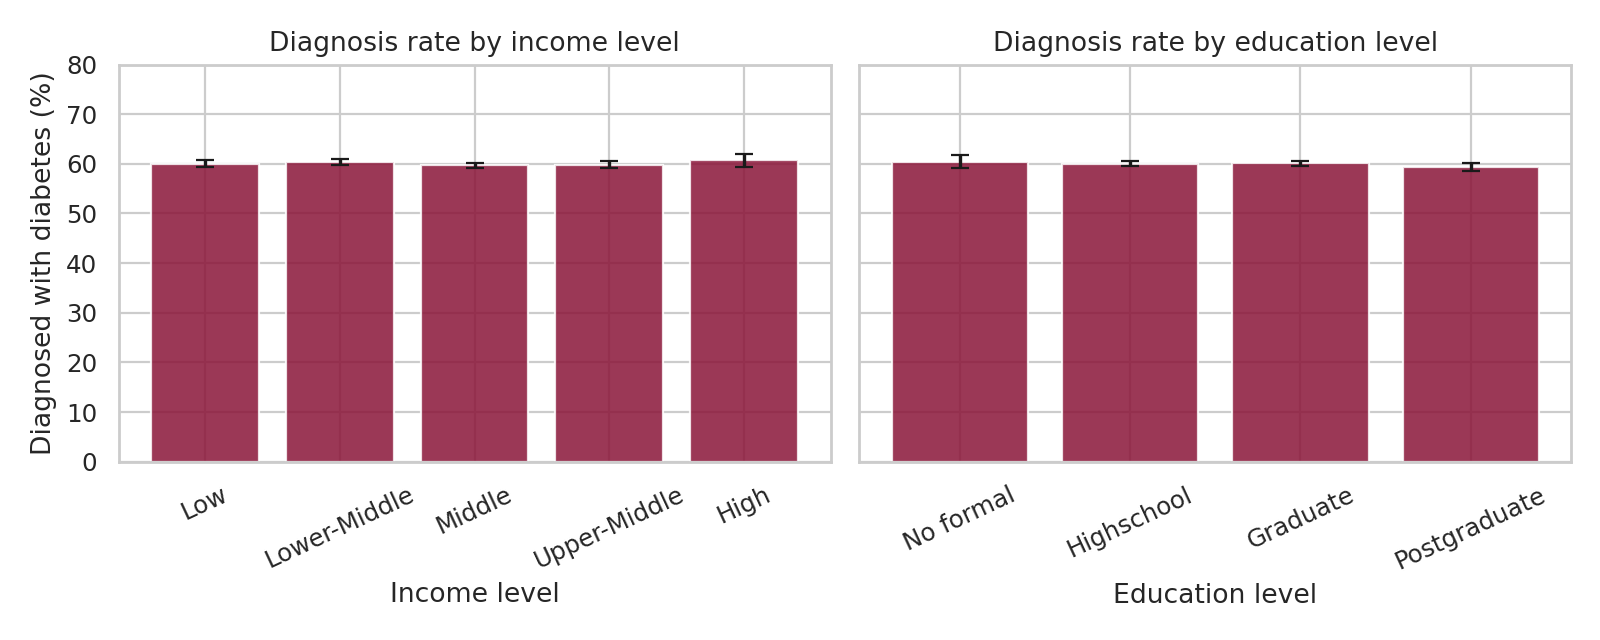

In [6]:
display(Image('../results/figures/03_ses_gradient_is_flat.png'))

## 4. Dose-response: activity and HbA1c

A binary 150-minute cutoff discards information. If activity truly matters, HbA1c should fall *monotonically* across activity levels.

In [7]:
dr = H.dose_response(df)
print(f"Spearman rho = {dr.attrs['spearman_rho']:.3f}, p = {dr.attrs['spearman_p']:.1e}")
dr

Spearman rho = -0.107, p = 5.4e-254


,activity_bin,count,mean,std,ci95
0,0-30,9627,6.6461,0.8167,0.0163
1,31-60,17778,6.6035,0.8064,0.0119
2,61-100,23104,6.5599,0.8091,0.0104
3,101-150,21318,6.5139,0.8061,0.0108
4,151-250,20289,6.4381,0.8090,0.0111
5,250+,7884,6.2978,0.8098,0.0179


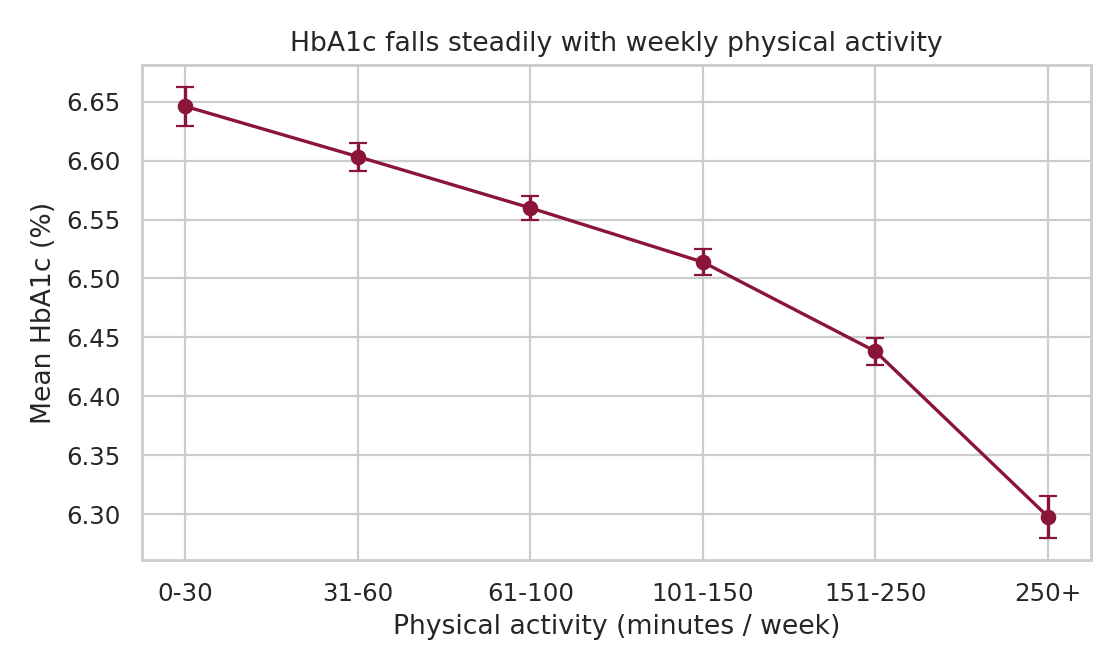

In [8]:
display(Image('../results/figures/01_activity_dose_response.png'))

HbA1c declines at every step, from about 6.65% in the 0-30 minute group to about 6.30% in the 250+ group. A clean gradient makes a threshold artefact unlikely, though it still cannot establish causation (people with worse glycaemic control may also exercise less).

## 5. Exploratory: does the activity effect differ by income or age?

*Exploratory, not part of the Holm family.* This asks a policy-relevant question: would an exercise programme help some groups more? I test activity x moderator interactions with F-tests.

In [9]:
het = H.heterogeneity(df)
het

,moderator,level,n,slope_per_100min,ci_low,ci_high,interaction_F,interaction_p
0,income,High,5002,-0.1252,-0.1524,-0.0980,0.9294,0.4456
1,income,Low,14830,-0.0984,-0.1136,-0.0833,0.9294,0.4456
2,income,Lower-Middle,25150,-0.1131,-0.1249,-0.1014,0.9294,0.4456
3,income,Middle,35152,-0.1086,-0.1187,-0.0985,0.9294,0.4456
4,income,Upper-Middle,19866,-0.1077,-0.1211,-0.0944,0.9294,0.4456
5,age_group,18-39,25573,-0.1011,-0.1128,-0.0895,3.4006,0.0334
6,age_group,40-59,46812,-0.1068,-0.1154,-0.0982,3.4006,0.0334
7,age_group,60+,27615,-0.1215,-0.1327,-0.1103,3.4006,0.0334


- **Income:** no evidence of heterogeneity (interaction p = 0.45). The slope is similar (about -0.10 to -0.13 HbA1c points per 100 min) in every income group.
- **Age:** a nominal interaction (p = 0.033) with a slightly steeper slope for 60+ (-0.12 vs -0.10). This was one of several exploratory tests and would not survive correction for multiplicity, so I treat it as a hypothesis for future work, not a finding.

## 6. Adjusted model: which factors matter jointly?

Logistic regression for diagnosis with continuous predictors standardised (odds ratio per 1 SD), robust standard errors. **HbA1c, glucose and insulin are excluded on purpose**, because they are diagnostic criteria and would make the model circular.

In [10]:
lg = H.adjusted_logit(df)
print("n =", lg.attrs["n"], " McFadden pseudo-R2 =", round(lg.attrs["pseudo_r2"], 3))
lg[~lg.term.str.contains(r"C\(")].sort_values("odds_ratio", ascending=False)

n = 100000  McFadden pseudo-R2 = 0.06


,term,odds_ratio,or_low,or_high,p
29,family_history_diabetes,3.0876,2.9794,3.1997,0.0000
18,age_z,1.3146,1.2929,1.3367,0.0000
19,bmi_z,1.1223,1.0979,1.1473,0.0000
31,cardiovascular_history,1.0876,1.0342,1.1437,0.0011
28,triglycerides_z,1.0456,1.0305,1.0609,0.0000
24,screen_time_hours_per_day_z,1.0445,1.0308,1.0584,0.0000
27,ldl_cholesterol_z,1.0274,1.0130,1.0420,0.0002
20,waist_to_hip_ratio_z,1.0230,1.0022,1.0442,0.0302
26,systolic_bp_z,1.0126,0.9963,1.0291,0.1317
30,hypertension_history,1.0118,0.9808,1.0438,0.4603


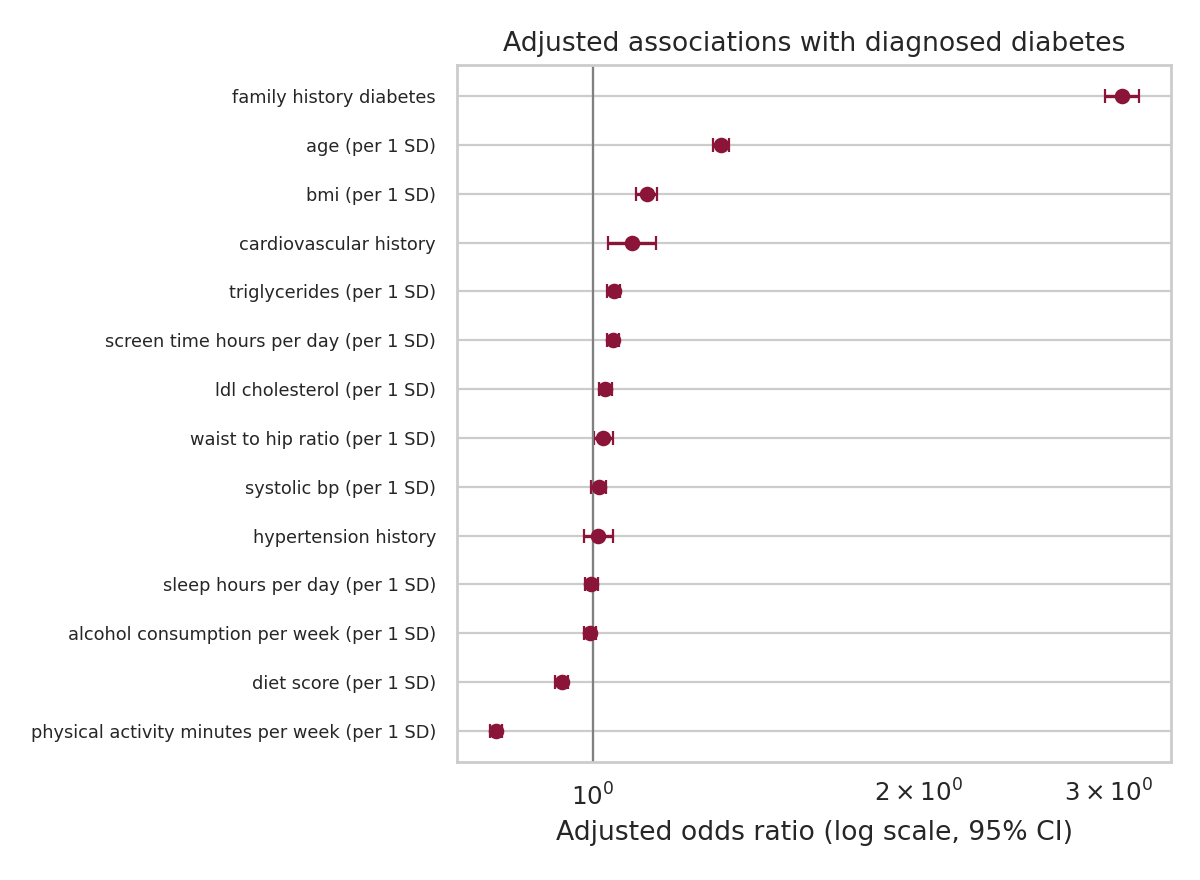

In [11]:
display(Image('../results/figures/04_adjusted_odds_ratios.png'))

After adjustment the ordering is stable: **family history (OR about 3.1)**, **age (1.32 per SD)**, **BMI (1.12 per SD)** and **physical activity (0.81 per SD, protective)**. Diet, screen time, LDL and triglycerides have small but detectable ORs (0.94 to 1.05). Income, education, smoking, ethnicity and employment are all close to 1. The model explains only about 6% of variance (pseudo-R2), so most of the variation in diagnosis is not captured by observed lifestyle and background factors.

## 7. How predictable is diagnosis? A benchmark ladder

5-fold cross-validated AUC as predictor blocks are added. This quantifies how much each domain contributes and exposes the circularity of glycaemic markers.

In [12]:
lad = H.predictive_ladder(df)
lad

,model,auc_mean,auc_sd
0,1. Demographics + SES,0.5797,0.0017
1,2. + Behaviour,0.6024,0.0016
2,3. + Body & clinical,0.6609,0.0025
3,4. + Glycaemic markers (circular),0.9340,0.0011


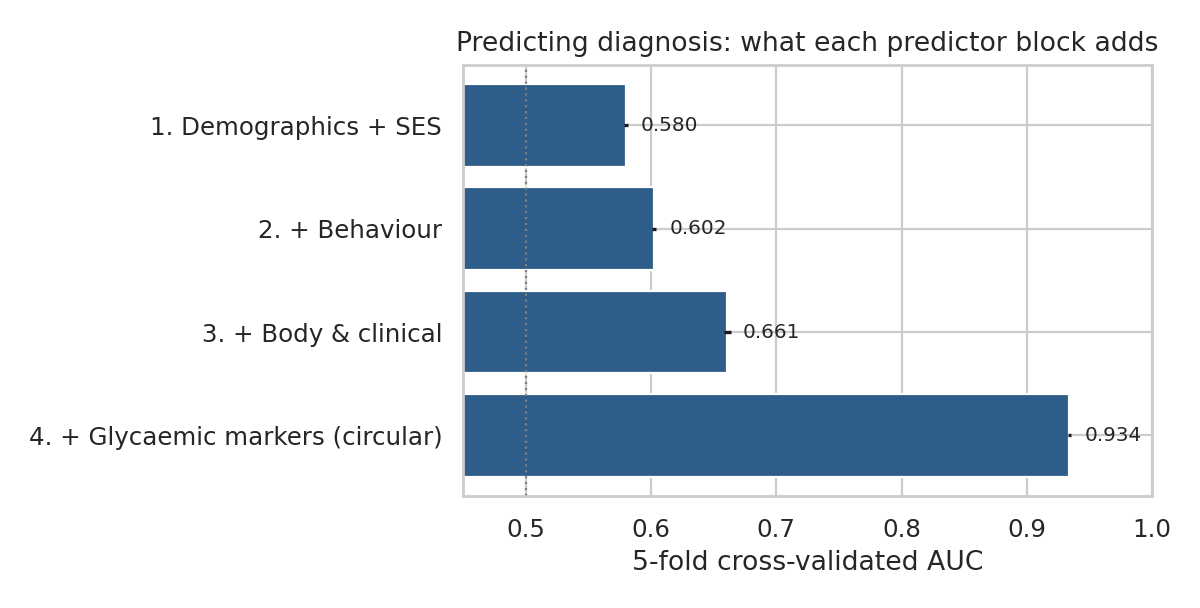

In [13]:
display(Image('../results/figures/05_auc_ladder.png'))

Demographics and SES alone barely beat a coin flip (AUC 0.58). Behaviour adds a little (0.60), and body/clinical measures plus family history reach 0.66. Adding HbA1c, glucose and insulin jumps to 0.93, but that is **measurement, not prediction**: these variables define the outcome. The honest, policy-relevant model is the 0.66 one, and it is modest.

## 8. Summary and limitations

**What the data support**
1. Behavioural associations are real but **small**: activity (d = -0.21), diet (d = -0.13), obesity (d = +0.23).
2. Family history is the dominant observable risk factor (OR about 3).
3. SES, smoking and ethnicity show no association, and equivalence tests confirm those gaps are small.
4. Observable lifestyle and background variables explain little of who is diagnosed (AUC 0.66 without glycaemic markers).

**Limitations**
- **Probably synthetic data**: unrealistic prevalence (60%) and absent SES gradients. Findings should not be generalised to real populations.
- **Cross-sectional and observational**: associations only. Reverse causality and confounding (e.g. people with diabetes may exercise less because of it) cannot be ruled out.
- **Outcome definition**: pre-diabetes is coded as undiagnosed, and HbA1c is only partly aligned with the recorded stage (85% of Type 2 cases have HbA1c >= 6.5).
- **Cut-offs and margins** (150 min, BMI 30, +/- 3 pp) are conventional or judgement-based and were fixed before testing.

**If I had real data (natural next steps)**: use panel or quasi-experimental variation (e.g. policy changes, instruments) to move from association toward causal estimates; model heterogeneity with pre-registered subgroups; and replicate on a nationally representative survey such as NHANES.